# TP3 (Big) : estimer la valeur marchande des joueurs avec Spark 💶

- **Auteur :** Hugo EXERTIER (ID 06)
- **Cours :** Big Data, 5A (Mohamed Quafafou), rendu du 18/11/2026
- **Partie :** TP3, cas personnel n° 2, *big data* (dossier `Big/`)
- **Dataset Kaggle :** [Football Data from Transfermarkt](https://www.kaggle.com/datasets/davidcariboo/player-scores) (davidcariboo) : environ 930 Mo de CSV, **1,9 M de matchs joués**, 1,3 M d'événements de match, 656 000 valeurs marchandes, 50 000 joueurs
- **Notebooks d'origine :** [football-player-market-value-prediction](https://github.com/Anubhav1989/football-player-market-value-prediction) (Anubhav1989) : 8 notebooks pandas / scikit-learn sur ce même dataset, qui prédisent `log(1 + valeur marchande)` d'un joueur à partir de son profil et de ses performances

**Question posée :** *à partir des performances d'un joueur sur une saison et de son profil, peut-on estimer sa valeur marchande ?*

## Contribution

### Le notebook est-il correct ?

- **Ce notebook : oui.** Il s'exécute de bout en bout, sans erreur (environ 10 minutes sur une machine à 20 cœurs). Il faut **Java 17 ou 21** pour PySpark 4 (sous Windows, utiliser WSL ou Docker) et les données dans `data/raw/` (`python scripts/download_data.py`).
- **Les notebooks d'origine ne s'exécutent pas de bout en bout à partir du dépôt**, et ils n'utilisent pas PySpark.

### Problèmes rencontrés dans les notebooks d'origine

1. **Fichier manquant** : `appearances.csv` (≈ 200 Mo, 1,9 M de lignes) n'est pas dans le dépôt, donc le notebook `05_feature_engineering` s'arrête à la première cellule tant qu'on ne l'a pas téléchargé depuis Kaggle.
2. **Déploiement incomplet** : le README demande de lancer `python app.py` (app Flask), mais `app.py` n'est pas dans le dépôt.
3. **Une seule photo des données** : on ne garde que les joueurs actifs en 2025 avec leur valeur actuelle, soit une ligne par joueur. Les 656 000 évaluations historiques ne servent pas, et les performances ne portent que sur les 12 derniers mois.
4. **Découpage aléatoire** (`train_test_split`) : on ne vérifie pas que le modèle sait prédire une saison future à partir des saisons passées.
5. **Pas de big data** : tout est chargé en mémoire avec pandas, alors que la table des matchs fait 1,9 M de lignes. Le même code de préparation est aussi recopié dans plusieurs notebooks (04, 06, 07, 08).

### Modifications apportées

- **Tout le traitement est refait avec PySpark** : conversion des CSV en **Parquet**, agrégations Spark sur les 1,9 M de matchs, **fonctions de fenêtre** (dernière valeur de chaque saison, valeur de la saison précédente avec `lag`), jointures **broadcast**, pipelines **Spark ML** et `CrossValidator`.
- **Une ligne par joueur et par saison** (79 642 lignes sur 2013-2025) au lieu d'une ligne par joueur, avec des performances plus riches (matchs de championnat, de coupe et de coupe d'Europe, titularisations, stats par 90 minutes).
- **Découpage temporel** : entraînement sur 2013-2022, test sur 2023-2025.
- On garde l'idée des notebooks d'origine de comparer deux jeux de variables : **A** (performances + profil, comme leur modèle « profil + performances ») et **B** (A + valeur de la saison précédente).
- **Déploiement complet** : pipeline Spark sauvegardé, job de scoring batch `src/score.py` (`spark-submit`), app **Streamlit** qui lit les prédictions, images **Docker** et `docker-compose`.
- Code de préparation écrit une seule fois dans `src/features.py`, partagé entre le notebook et le job de scoring.

### Autres informations

- Résultat : GBT optimisé (scénario B), **R² = 0,906** sur les saisons de test (erreur relative médiane de 25 %). Sans la valeur précédente (scénario A), R² = 0,734. Les notebooks d'origine obtiennent R² = 0,736 avec un Gradient Boosting optimisé, mais sur un découpage aléatoire d'une seule saison : les deux chiffres ne se comparent donc pas directement.
- Le téléchargement direct depuis Kaggle sans compte ne fonctionne plus (erreur 404). `scripts/download_data.py` passe alors par le miroir officiel de l'auteur du dataset (lien « Download Dataset » de [dcaribou/transfermarkt-datasets](https://github.com/dcaribou/transfermarkt-datasets)), qui contient les mêmes tables.
- Chaque section commence par une cellule `## [Étape]`.

| # | Étape | Contenu |
|---|---|---|
| 1 | **Data** | session Spark, lecture des CSV, conversion en **Parquet** |
| 2 | **EDA** | agrégations Spark sur les millions de lignes (valeurs par poste, âge, championnat, évolution) |
| 3 | **Prétraitement** | valeurs manquantes, valeurs aberrantes, définition des saisons |
| 4 | **Transformation** | **agrégation de 1,9 M de matchs → stats par joueur et par saison**, jointure avec la valeur marchande, features |
| 5 | **ML** | Pipelines **Spark ML** : régression linéaire, Random Forest, GBT ; avec / sans historique de valeur |
| 6 | **Éval** | découpage **temporel**, RMSE / MAE / R², `CrossValidator`, importance des variables, erreurs en € |
| 7 | **Déploiement** | modèle Spark sauvegardé + job batch `src/score.py` + app **Streamlit** |

In [1]:
import sys, os, json, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

# Sur Kaggle / Colab : récupérer le module src/features.py depuis le repo GitHub si absent
try:
    from src import features as T
except ImportError:
    GITHUB_RAW = "https://raw.githubusercontent.com/ItaTuTsuki/TP3_ID06/main/Big/src/features.py"
    os.makedirs("src", exist_ok=True); open("src/__init__.py", "a").close()
    import urllib.request; urllib.request.urlretrieve(GITHUB_RAW, "src/features.py")
    ROOT = Path.cwd(); from src import features as T

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import functions as F, Window

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

## [Data]

## 1. Data

### 1.1 Session Spark

Spark tourne ici en mode **local** (`local[*]` = un exécuteur par cœur CPU). Le même code tourne sans modification sur un **cluster** (YARN, Kubernetes, Databricks…) en changeant seulement `master` : c'est tout l'intérêt de Spark.

In [2]:
spark = T.get_spark("transfermarkt-notebook", memory="4g")
print("Spark", spark.version, "| master :", spark.sparkContext.master,
      "| parallélisme :", spark.sparkContext.defaultParallelism)
DATA_DIR = T.find_data_dir()
print("Données :", DATA_DIR)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/18 22:24:38 WARN Utils: Your hostname, Hugofix, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/18 22:24:38 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/18 22:24:39 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.0.1 | master : local[*] | parallélisme : 20
Données : /mnt/d/Cours/Marseille/5A/big_data/tp3/Big/data/raw


### 1.2 Les fichiers bruts

In [3]:
sizes = pd.DataFrame([(p.name, p.stat().st_size / 1e6) for p in sorted(DATA_DIR.glob("*.csv"))],
                     columns=["fichier", "taille (Mo)"]).set_index("fichier").round(1)
print(f"Total : {sizes['taille (Mo)'].sum():.0f} Mo")
sizes.sort_values("taille (Mo)", ascending=False)

Total : 915 Mo


,taille (Mo)
fichier,
game_lineups.csv,416.0
appearances.csv,198.4
game_events.csv,179.1
player_valuations.csv,39.6
games.csv,29.0
players.csv,19.6
transfers.csv,18.1
club_games.csv,14.7
clubs.csv,0.2


### 1.3 Conversion CSV → Parquet

Le CSV est un format texte : il faut tout relire et re-deviner les types à chaque lecture.
**Parquet** est un format **colonnes**, compressé et typé — le standard du big data (Spark, Hive, Databricks…).
On convertit une fois ; toutes les lectures suivantes sont beaucoup plus rapides.

In [4]:
PARQUET_DIR = ROOT / "data" / "parquet"
t0 = time.time()
T.csv_to_parquet(spark, DATA_DIR, PARQUET_DIR)
print(f"Conversion : {time.time() - t0:.0f} s")

def dir_size(p): return sum(f.stat().st_size for f in Path(p).rglob("*") if f.is_file()) / 1e6
comp = pd.DataFrame({"CSV (Mo)": [(DATA_DIR / f"{t}.csv").stat().st_size / 1e6 for t in T.TABLES],
                     "Parquet (Mo)": [dir_size(PARQUET_DIR / t) for t in T.TABLES]}, index=T.TABLES).round(1)
comp.loc["TOTAL"] = comp.sum()
comp

Conversion : 22 s


,CSV (Mo),Parquet (Mo)
appearances,198.4,31.5
player_valuations,39.6,6.0
players,19.6,5.4
competitions,0.0,0.0
clubs,0.2,0.1
games,29.0,4.3
transfers,18.1,4.4
TOTAL,304.9,51.7


In [5]:
tables = T.load_tables(spark, DATA_DIR, PARQUET_DIR)
counts = {name: df.count() for name, df in tables.items()}
pd.Series(counts, name="lignes").to_frame().style.format("{:,}")

,lignes
appearances,"1,894,350"
player_valuations,"656,301"
players,"50,149"
competitions,65
clubs,796
games,"88,958"
transfers,"175,165"


In [6]:
apps, vals, players, comps = tables["appearances"], tables["player_valuations"], tables["players"], tables["competitions"]
apps.printSchema()
apps.show(5, truncate=False)

root
 |-- appearance_id: string (nullable = true)
 |-- game_id: integer (nullable = true)
 |-- player_id: integer (nullable = true)
 |-- player_club_id: integer (nullable = true)
 |-- player_current_club_id: integer (nullable = true)
 |-- date: date (nullable = true)
 |-- player_name: string (nullable = true)
 |-- competition_id: string (nullable = true)
 |-- yellow_cards: integer (nullable = true)
 |-- red_cards: integer (nullable = true)
 |-- goals: integer (nullable = true)
 |-- assists: integer (nullable = true)
 |-- minutes_played: integer (nullable = true)



+--------------+-------+---------+--------------+----------------------+----------+----------------+--------------+------------+---------+-----+-------+--------------+
|appearance_id |game_id|player_id|player_club_id|player_current_club_id|date      |player_name     |competition_id|yellow_cards|red_cards|goals|assists|minutes_played|
+--------------+-------+---------+--------------+----------------------+----------+----------------+--------------+------------+---------+-----+-------+--------------+
|4275925_188888|4275925|188888   |681           |331                   |2024-02-27|Sheraldo Becker |CDR           |0           |0        |0    |0      |74            |
|4275925_198008|4275925|198008   |681           |1531                  |2024-02-27|André Silva     |CDR           |0           |0        |0    |0      |46            |
|4275925_212862|4275925|212862   |681           |681                   |2024-02-27|Álex Remiro     |CDR           |0           |0        |0    |0      |120     

In [7]:
vals.show(5, truncate=False)
players.select("player_id", "name", "date_of_birth", "position", "sub_position", "foot", "height_in_cm",
               "market_value_in_eur").show(5, truncate=False)

+---------+----------+-------------------+------------------+---------------+-----------------------------------+
|player_id|date      |market_value_in_eur|current_club_name |current_club_id|player_club_domestic_competition_id|
+---------+----------+-------------------+------------------+---------------+-----------------------------------+
|204045   |2021-12-20|300000             |Chornomorets Odesa|6992           |UKR1                               |
|204348   |2021-12-20|300000             |FK Minaj          |61825          |UKR1                               |
|206888   |2021-12-20|9000000            |Dynamo Kyiv       |338            |UKR1                               |
|207074   |2021-12-20|1200000            |Dynamo Kyiv       |338            |UKR1                               |
|208469   |2021-12-20|500000             |Rukh Lviv         |338            |UKR1                               |
+---------+----------+-------------------+------------------+---------------+-----------

+---------+--------------+-------------------+--------+------------------+-----+------------+-------------------+
|player_id|name          |date_of_birth      |position|sub_position      |foot |height_in_cm|market_value_in_eur|
+---------+--------------+-------------------+--------+------------------+-----+------------+-------------------+
|351504   |John Nelson   |1998-07-11 00:00:00|Defender|Left-Back         |left |175         |800000             |
|351505   |Álex Zendejas |1998-02-07 00:00:00|Attack  |Right Winger      |left |167         |10000000           |
|351506   |Joshua Pérez  |1998-01-21 00:00:00|Midfield|Attacking Midfield|left |165         |150000             |
|351524   |Eirik Wichne  |1997-05-12 00:00:00|Defender|Right-Back        |right|174         |350000             |
|351526   |Ali Al-Busaidi|1991-01-21 00:00:00|Defender|Left-Back         |left |172         |150000             |
+---------+--------------+-------------------+--------+------------------+-----+--------

## [EDA]

## 2. EDA — Analyse exploratoire

Toutes les agrégations sont calculées **par Spark** sur les données complètes ; seul le petit résultat agrégé est rapatrié en pandas (`toPandas()`) pour les graphiques.

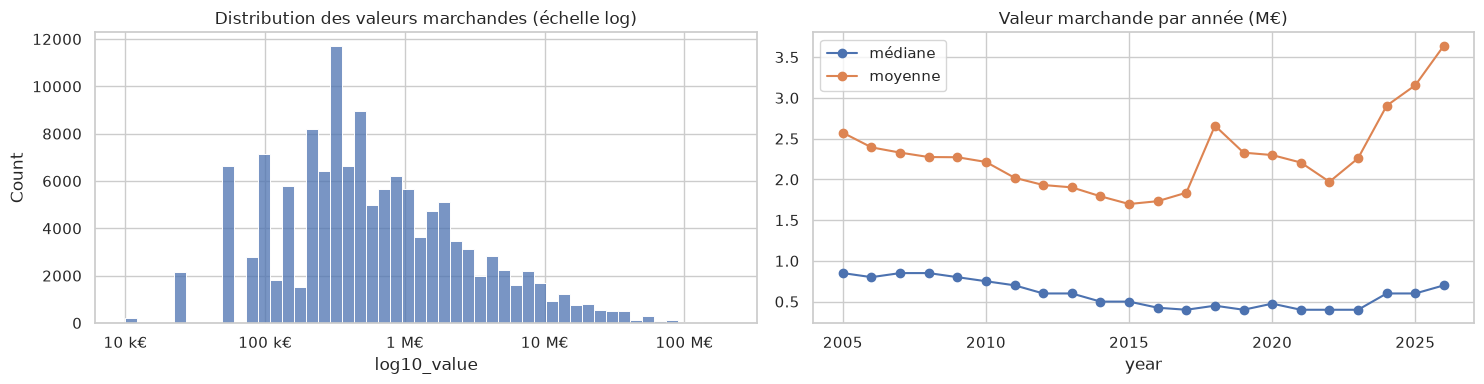

In [8]:
v = vals.filter("market_value_in_eur > 0").withColumn("year", F.year("date"))
dist = v.select((F.log10("market_value_in_eur")).alias("log10_value")).sample(0.2, seed=42).toPandas()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(dist["log10_value"], bins=50, ax=axes[0])
axes[0].set_xticks(range(4, 9)); axes[0].set_xticklabels(["10 k€", "100 k€", "1 M€", "10 M€", "100 M€"])
axes[0].set_title("Distribution des valeurs marchandes (échelle log)")
per_year = v.groupBy("year").agg(F.expr("percentile_approx(market_value_in_eur, 0.5)").alias("médiane"),
                                 F.avg("market_value_in_eur").alias("moyenne"),
                                 F.count("*").alias("n")).filter("year >= 2005").orderBy("year").toPandas()
(per_year.set_index("year")[["médiane", "moyenne"]] / 1e6).plot(ax=axes[1], marker="o")
axes[1].set_title("Valeur marchande par année (M€)")
plt.tight_layout(); plt.show()

- La valeur marchande est **extrêmement asymétrique** (de 10 k€ à 200 M€) : on prédira son **logarithme**, sinon le modèle ne s'intéresserait qu'aux stars.
- **Inflation** : la valeur moyenne augmente avec les années (droits TV, marché des transferts) → la saison sera une variable du modèle, et l'évaluation devra être **temporelle**.

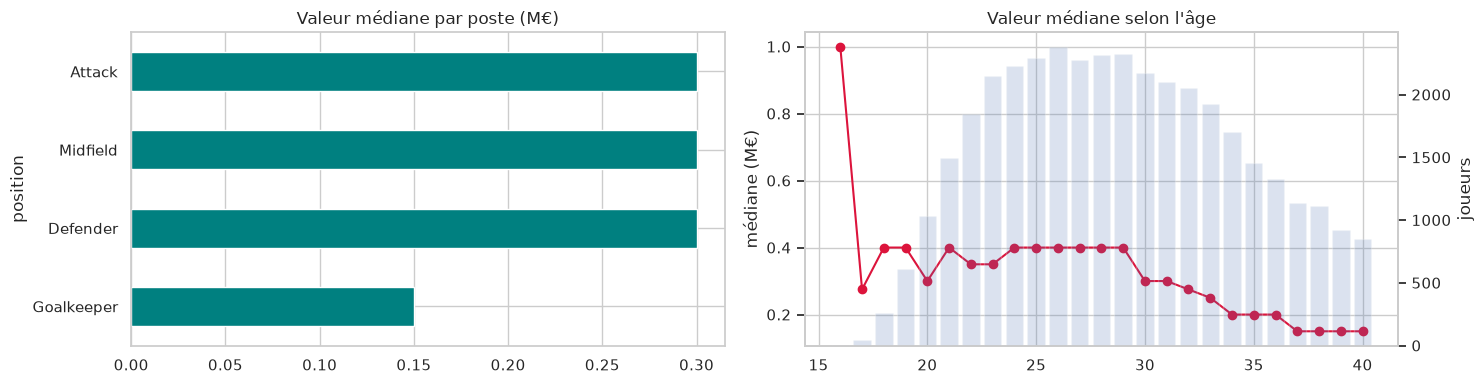

In [9]:
latest = (players.filter("market_value_in_eur > 0 AND position != 'Missing'")
          .withColumn("age", F.floor(F.datediff(F.current_date(), F.to_date("date_of_birth")) / 365.25)))
by_pos = latest.groupBy("position").agg(F.expr("percentile_approx(market_value_in_eur, 0.5)").alias("median")).toPandas()
by_age = (latest.filter("age BETWEEN 16 AND 40").groupBy("age")
          .agg(F.expr("percentile_approx(market_value_in_eur, 0.5)").alias("median"), F.count("*").alias("n"))
          .orderBy("age").toPandas())

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
(by_pos.set_index("position")["median"].sort_values() / 1e6).plot.barh(ax=axes[0], color="teal", title="Valeur médiane par poste (M€)")
ax2 = axes[1].twinx()
axes[1].plot(by_age["age"], by_age["median"] / 1e6, marker="o", color="crimson"); axes[1].set_ylabel("médiane (M€)")
ax2.bar(by_age["age"], by_age["n"], alpha=0.2); ax2.set_ylabel("joueurs"); ax2.grid(False)
axes[1].set_title("Valeur médiane selon l'âge")
plt.tight_layout(); plt.show()

La valeur culmine vers **24-27 ans** puis chute : l'âge sera une variable clé, avec un effet **non linéaire** (avantage aux modèles à base d'arbres).

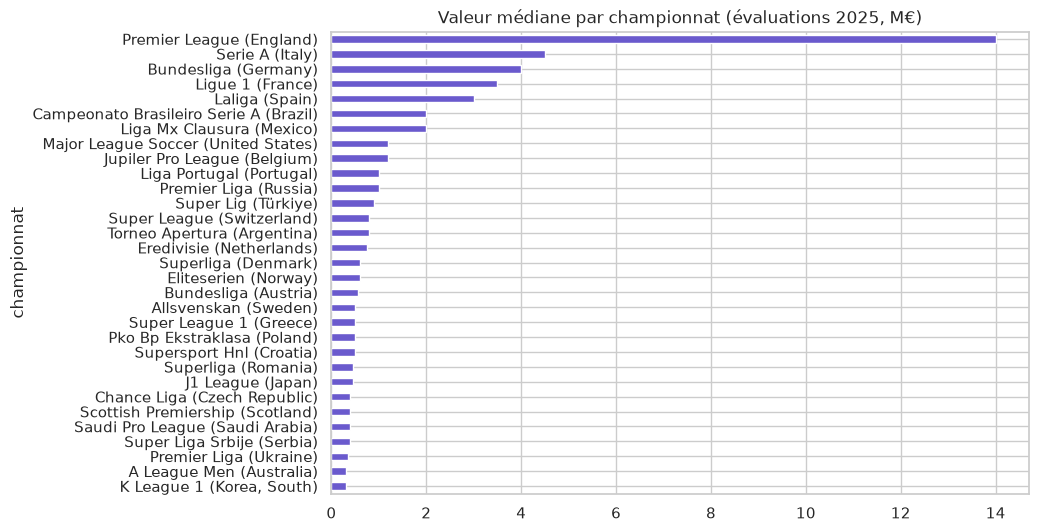

In [10]:
by_league = (v.filter("year = 2025")
             .join(comps.select(F.col("competition_id").alias("player_club_domestic_competition_id"), "name", "country_name"),
                   "player_club_domestic_competition_id")
             .groupBy("country_name", "name")
             .agg(F.expr("percentile_approx(market_value_in_eur, 0.5)").alias("median"), F.count("*").alias("n"))
             .filter("n > 300").orderBy(F.desc("median")).toPandas())
by_league["championnat"] = by_league["name"].str.replace("-", " ").str.title() + " (" + by_league["country_name"] + ")"
(by_league.set_index("championnat")["median"].sort_values() / 1e6).plot.barh(figsize=(9, 6), color="slateblue")
plt.title("Valeur médiane par championnat (évaluations 2025, M€)"); plt.show()

In [11]:
top = (players.filter("market_value_in_eur IS NOT NULL")
       .orderBy(F.desc("market_value_in_eur"))
       .select("name", "position", "current_club_name", (F.col("market_value_in_eur") / 1e6).alias("valeur (M€)"))
       .limit(10).toPandas())
top

,name,position,current_club_name,valeur (M€)
0,Lamine Yamal,Attack,FC Barcelona,200.0
1,Erling Haaland,Attack,Manchester City,200.0
2,Kylian Mbappé,Attack,Real Madrid,180.0
3,Pedri,Midfield,FC Barcelona,150.0
4,Michael Olise,Attack,Bayern Munich,150.0
5,João Neves,Midfield,Paris Saint-Germain,140.0
6,Vinicius Junior,Attack,Real Madrid,140.0
7,Vitinha,Midfield,Paris Saint-Germain,140.0
8,Khvicha Kvaratskhelia,Attack,Paris Saint-Germain,140.0
9,Jude Bellingham,Midfield,Real Madrid,130.0


In [12]:
# Volume de données par championnat : nombre de matchs joués enregistrés
(apps.join(comps.select("competition_id", "type"), "competition_id", "left")
     .groupBy("type").count().orderBy(F.desc("count")).toPandas())

,type,count
0,domestic_league,1606102
1,domestic_cup,118769
2,other,91729
3,international_cup,60523
4,NaN,14200
5,national_team_competition,3027


## [Prétraitement]

## 3. Prétraitement

### 3.1 Valeurs manquantes

In [13]:
def null_report(df, name):
    n = df.count()
    row = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).first().asDict()
    return pd.Series({k: v / n for k, v in row.items() if v}, name=name)

pd.concat([null_report(players.select("date_of_birth", "position", "sub_position", "foot", "height_in_cm"), "players"),
           null_report(vals, "player_valuations"),
           null_report(apps.select("date", "minutes_played", "goals", "assists"), "appearances")], axis=1).map(
    lambda x: f"{x:.1%}" if pd.notna(x) else "")

,players,player_valuations,appearances
date_of_birth,0.1%,,
sub_position,1.2%,,
foot,11.8%,,
height_in_cm,8.7%,,
player_club_domestic_competition_id,,14.2%,


Décisions (codées dans `src/features.py`) :

| Problème | Traitement |
|---|---|
| `position = "Missing"` (≈ 1 %) | joueur exclu |
| `foot`, `height_in_cm` manquants | catégorie « inconnue » (`handleInvalid="keep"`) / imputation par la médiane |
| championnat du club manquant dans `player_valuations` | catégorie `"Autre"` |
| valeur marchande = 0 | supprimée (pas une vraie estimation) |
| âge aberrant (date de naissance erronée) | on garde 15–45 ans |
| joueurs ayant très peu joué | on garde ≥ 90 minutes dans la saison |

### 3.2 Saison

Une saison européenne va de **juillet à juin** : un match du 15/03/2024 appartient à la saison 2023 (2023/24).

In [14]:
import inspect
print(inspect.getsource(T.season_col))
apps.select("date", T.season_col("date").alias("season")).distinct().orderBy("date").show(3)

def season_col(date_col: str = "date"):
    """Saison européenne : de juillet Y à juin Y+1 -> saison Y."""
    d = F.col(date_col)
    return F.when(F.month(d) >= 7, F.year(d)).otherwise(F.year(d) - 1)



+----------+------+
|      date|season|
+----------+------+
|2012-07-03|  2012|
|2012-07-05|  2012|
|2012-07-09|  2012|
+----------+------+
only showing top 3 rows


## [Transformation]

## 4. Transformation — le cœur « big data »

### 4.1 Agréger 1,9 M de matchs en stats par joueur et par saison

Pour chaque joueur et chaque saison : nombre de matchs, minutes, buts, passes décisives, cartons, matchs en championnat / coupe / **coupes d'Europe**, part de titularisations, ratios par 90 minutes.
C'est un `groupBy` distribué sur 1,9 M de lignes, avec une jointure **broadcast** (la petite table des compétitions est envoyée à tous les exécuteurs pour éviter un shuffle).

In [15]:
print(inspect.getsource(T.season_stats))

def season_stats(appearances: DataFrame, competitions: DataFrame, games: DataFrame | None = None) -> DataFrame:
    """Agrège ~1,9 M de lignes de matchs en stats par (joueur, saison)."""
    comp = competitions.select(
        "competition_id",
        F.col("type").alias("comp_type"),
        F.col("sub_type").alias("comp_sub_type"),
    )
    apps = (
        appearances.join(F.broadcast(comp), "competition_id", "left")
        .withColumn("season", season_col("date"))
        .withColumn("is_league", F.coalesce(F.col("comp_type") == "domestic_league", F.lit(False)).cast("int"))
        .withColumn("is_cup", F.coalesce(F.col("comp_type") == "domestic_cup", F.lit(False)).cast("int"))
        .withColumn("is_europe", F.coalesce(F.col("comp_sub_type").startswith("uefa_"), F.lit(False)).cast("int"))
        .withColumn("is_starter", (F.col("minutes_played") >= 60).cast("int"))
    )
    agg = apps.groupBy("player_id", "season").agg(
        F.count("*").alias("matches"),
        F.sum("m

In [16]:
stats = T.season_stats(apps, comps)
stats.orderBy(F.desc("goals")).show(5)

+---------+------+-------+-------+-----+-------+------------+---------+--------------+-----------+--------------+------------------+------------------+-------------------+-----------------+
|player_id|season|matches|minutes|goals|assists|yellow_cards|red_cards|matches_league|matches_cup|matches_europe|     starter_share|       goals_per90|      assists_per90|minutes_per_match|
+---------+------+-------+-------+-----+-------+------------+---------+--------------+-----------+--------------+------------------+------------------+-------------------+-----------------+
|   132098|  2025|     54|   4314|   61|      7|           3|        0|            31|          5|            13|0.8703703703703703|1.2726008344923505|0.14603616133518776|79.88888888888889|
|     8198|  2014|     54|   4641|   61|     23|           6|        1|            35|          2|            13|0.9259259259259259| 1.182934712346477|0.44602456367162246|85.94444444444444|
|    28003|  2012|     50|   4070|   60|     17|  

### 4.2 La cible : la valeur marchande de fin de saison

Un joueur est réévalué plusieurs fois par saison. Avec une **fonction de fenêtre** (`Window` + `row_number`), on garde la **dernière valeur de chaque saison**, et avec `lag` celle de la **saison précédente** (variable d'historique).

In [17]:
print(inspect.getsource(T.season_values))

def season_values(valuations: DataFrame) -> DataFrame:
    """Cible : dernière valeur marchande de chaque joueur sur chaque saison (+ celle de la saison précédente)."""
    v = (
        valuations.filter(F.col("market_value_in_eur") > 0)
        .withColumn("season", season_col("date"))
    )
    last = Window.partitionBy("player_id", "season").orderBy(F.col("date").desc())
    v = (
        v.withColumn("rn", F.row_number().over(last)).filter("rn = 1")
        .select(
            "player_id", "season",
            F.col("date").alias("value_date"),
            F.col("market_value_in_eur").alias("market_value"),
            F.coalesce(F.col("player_club_domestic_competition_id"), F.lit("Autre")).alias("league"),
            F.col("current_club_name").alias("club_name"),
        )
        .withColumn(LABEL, F.log1p("market_value"))
    )
    prev = Window.partitionBy("player_id").orderBy("season")
    return v.withColumn(
        "prev_log_value",
        F.when(F.lag("season").over(p

### 4.3 Dataset final : jointures + âge + filtres

In [18]:
t0 = time.time()
data = T.build_dataset(tables).cache()
n = data.count()
print(f"{n:,} lignes joueur × saison construites en {time.time() - t0:.0f} s "
      f"(à partir de {counts['appearances']:,} matchs et {counts['player_valuations']:,} évaluations)")
data.select("name", "season", "club_name", "league", "position", "age", "matches", "minutes",
            "goals", "assists", "matches_europe", "market_value", "prev_log_value").show(5)

79,642 lignes joueur × saison construites en 4 s (à partir de 1,894,350 matchs et 656,301 évaluations)
+---------------+------+----------------+------+----------+------------------+-------+-------+-----+-------+--------------+------------+------------------+
|           name|season|       club_name|league|  position|               age|matches|minutes|goals|assists|matches_europe|market_value|    prev_log_value|
+---------------+------+----------------+------+----------+------------------+-------+-------+-----+-------+--------------+------------+------------------+
|  Dominik Greif|  2023|    RCD Mallorca|   ES1|Goalkeeper|27.170431211498972|      8|    810|    0|      0|             0|     2500000|14.220976332738882|
|  Marcos Senesi|  2023| AFC Bournemouth|   GB1|  Defender| 27.04722792607803|     36|   2680|    4|      5|             0|    22000000|16.906553056777135|
|Tino Livramento|  2023|Newcastle United|   GB1|  Defender| 21.53867214236824|     35|   1892|    1|      1|         

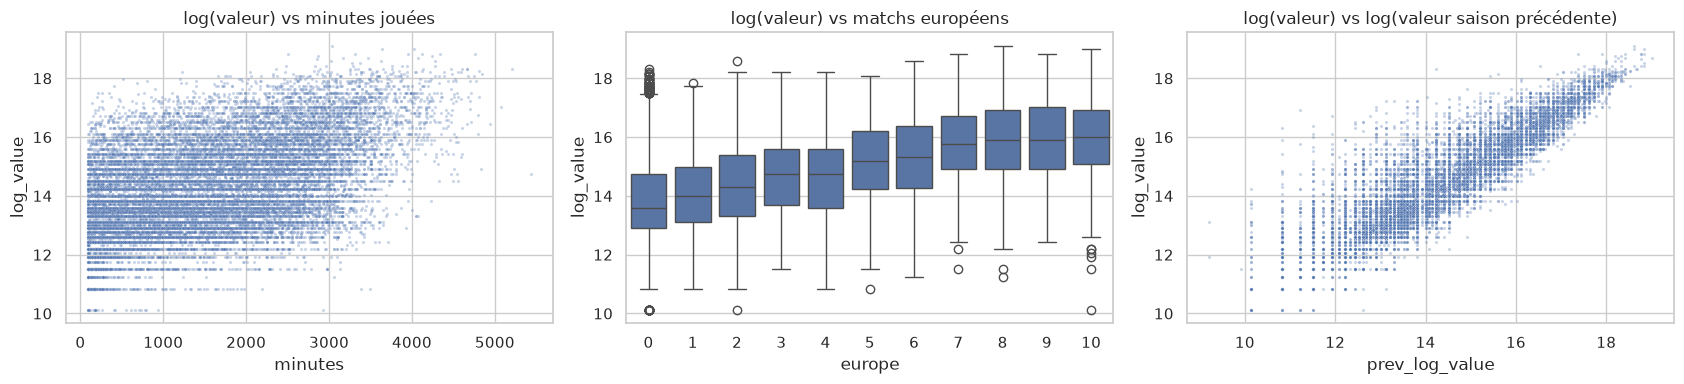

In [19]:
pdf = data.select(T.LABEL, "minutes", "goals_per90", "matches_europe", "age", "prev_log_value").sample(0.3, seed=1).toPandas()
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.scatterplot(data=pdf, x="minutes", y=T.LABEL, s=5, alpha=0.3, ax=axes[0]).set_title("log(valeur) vs minutes jouées")
sns.boxplot(data=pdf.assign(europe=pdf["matches_europe"].clip(upper=10)), x="europe", y=T.LABEL, ax=axes[1]).set_title("log(valeur) vs matchs européens")
sns.scatterplot(data=pdf, x="prev_log_value", y=T.LABEL, s=5, alpha=0.3, ax=axes[2]).set_title("log(valeur) vs log(valeur saison précédente)")
plt.tight_layout(); plt.show()

- Plus de **temps de jeu** et des **matchs européens** (= gros club) → valeur plus élevée.
- La valeur de la saison précédente est **très corrélée** à la valeur actuelle : c'est une variable puissante. On comparera donc deux scénarios :
  - **A — « recrutement »** : uniquement performances + profil (que vaut ce joueur au vu de sa saison ?) ;
  - **B — « mise à jour »** : A + valeur précédente (comment la valeur va-t-elle évoluer ?).

## [ML]

## 5. Machine Learning avec Spark ML

### 5.1 Découpage temporel

Pas de découpage aléatoire : on entraîne sur le **passé** (saisons 2013 → 2022) et on évalue sur le **futur** (2023 → 2025), comme en conditions réelles. Un découpage aléatoire mélangerait les saisons d'un même joueur entre train et test (fuite d'information).

In [20]:
# repartition(8) : ~60 000 lignes n'ont pas besoin de 16 partitions ; moins de partitions = moins
# de surcoût de planification à chaque itération du GBT (×5 plus rapide ici)
train = data.filter("season <= 2022").repartition(8).cache()
test = data.filter("season >= 2023").repartition(8).cache()
print(f"train : {train.count():,} lignes | test : {test.count():,} lignes")

train : 59,771 lignes | test : 19,871 lignes


### 5.2 Pipelines Spark ML

`StringIndexer` (catégories → indices) → `OneHotEncoder` (pour la régression linéaire) → `Imputer` (médiane) → `VectorAssembler` (toutes les features dans un vecteur) → modèle.
Le pipeline complet est **un seul objet** qu'on entraîne, sauvegarde et réapplique tel quel en production.

In [21]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, Imputer
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

def make_pipeline(model, numeric, one_hot):
    stages = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in T.CATEGORICAL]
    cat_cols = [f"{c}_idx" for c in T.CATEGORICAL]
    if one_hot:
        stages.append(OneHotEncoder(inputCols=cat_cols, outputCols=[f"{c}_ohe" for c in T.CATEGORICAL]))
        cat_cols = [f"{c}_ohe" for c in T.CATEGORICAL]
    to_impute = [c for c in ["height_in_cm", "prev_log_value"] if c in numeric]
    stages.append(Imputer(inputCols=to_impute, outputCols=to_impute, strategy="median"))
    stages.append(VectorAssembler(inputCols=numeric + cat_cols, outputCol="features"))
    stages.append(model)
    return Pipeline(stages=stages)

evaluators = {m: RegressionEvaluator(labelCol=T.LABEL, metricName=m) for m in ["rmse", "mae", "r2"]}
def evaluate(pred):
    return {m: e.evaluate(pred) for m, e in evaluators.items()}

MODELS = {
    "Régression linéaire": (lambda: LinearRegression(labelCol=T.LABEL, regParam=0.01), True),
    "Random Forest": (lambda: RandomForestRegressor(labelCol=T.LABEL, numTrees=100, maxDepth=10, maxBins=64, seed=42), False),
    "GBT": (lambda: GBTRegressor(labelCol=T.LABEL, maxIter=80, maxDepth=6, maxBins=64, seed=42), False),
}
SCENARIOS = {"A — performances + profil": T.NUMERIC_BASE, "B — A + valeur précédente": T.NUMERIC_WITH_HISTORY}

In [22]:
results, fitted = [], {}
for scen, numeric in SCENARIOS.items():
    for name, (factory, one_hot) in MODELS.items():
        t0 = time.time()
        model = make_pipeline(factory(), numeric, one_hot).fit(train)
        m = evaluate(model.transform(test))
        fitted[(scen, name)] = model
        results.append({"scénario": scen, "modèle": name, **m, "durée (s)": time.time() - t0})
        print(f"{scen:28s} {name:20s} RMSE={m['rmse']:.3f}  R²={m['r2']:.3f}  ({time.time() - t0:.0f} s)")
results = pd.DataFrame(results).set_index(["scénario", "modèle"]).round(3)
results

A — performances + profil    Régression linéaire  RMSE=0.889  R²=0.682  (4 s)


A — performances + profil    Random Forest        RMSE=0.841  R²=0.716  (23 s)


A — performances + profil    GBT                  RMSE=0.814  R²=0.734  (32 s)


B — A + valeur précédente    Régression linéaire  RMSE=0.589  R²=0.861  (2 s)


B — A + valeur précédente    Random Forest        RMSE=0.549  R²=0.879  (23 s)


B — A + valeur précédente    GBT                  RMSE=0.487  R²=0.905  (30 s)


rmse    mae     r2  durée (s)
scénario                  modèle                                             
A — performances + profil Régression linéaire  0.889  0.701  0.682      3.854
                          Random Forest        0.841  0.655  0.716     22.658
                          GBT                  0.814  0.623  0.734     31.541
B — A + valeur précédente Régression linéaire  0.589  0.422  0.861      1.918
                          Random Forest        0.549  0.389  0.879     22.511
                          GBT                  0.487  0.352  0.905     30.187

### 5.3 Optimisation des hyperparamètres (`CrossValidator`)

Validation croisée à 3 plis **sur le train uniquement**, sur une petite grille pour le GBT (le modèle le plus coûteux) — Spark entraîne les modèles candidats **en parallèle** (`parallelism`).

In [23]:
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

BEST_SCENARIO = "B — A + valeur précédente"
gbt = GBTRegressor(labelCol=T.LABEL, maxBins=64, seed=42)
grid = (ParamGridBuilder()
        .addGrid(gbt.maxDepth, [5, 7])
        .addGrid(gbt.maxIter, [60, 120])
        .build())
cv = CrossValidator(estimator=make_pipeline(gbt, SCENARIOS[BEST_SCENARIO], one_hot=False),
                    estimatorParamMaps=grid, evaluator=evaluators["rmse"],
                    numFolds=3, parallelism=2, seed=42)
t0 = time.time()
cv_model = cv.fit(train)
print(f"CrossValidator : {len(grid)} combinaisons × 3 plis en {time.time() - t0:.0f} s")
for params, rmse in zip(grid, cv_model.avgMetrics):
    print({p.name: v for p, v in params.items()}, f"RMSE CV = {rmse:.4f}")
best_model = cv_model.bestModel
best_params = {p.name: v for p, v in grid[int(pd.Series(cv_model.avgMetrics).idxmin())].items()}
print("Meilleurs paramètres :", best_params)

CrossValidator : 4 combinaisons × 3 plis en 373 s
{'maxDepth': 5, 'maxIter': 60} RMSE CV = 0.4595
{'maxDepth': 5, 'maxIter': 120} RMSE CV = 0.4415
{'maxDepth': 7, 'maxIter': 60} RMSE CV = 0.4585
{'maxDepth': 7, 'maxIter': 120} RMSE CV = 0.4543
Meilleurs paramètres : {'maxDepth': 5, 'maxIter': 120}


## [Éval]

## 6. Évaluation

### 6.1 Sur les saisons de test (2023 → 2025)

In [24]:
pred = best_model.transform(test).withColumn("pred_value", F.expm1("prediction")).cache()
best_metrics = evaluate(pred)
eur = (pred.select(F.abs(F.col("pred_value") - F.col("market_value")).alias("abs_err"),
                   (F.abs(F.col("pred_value") - F.col("market_value")) / F.col("market_value")).alias("ape"))
           .agg(F.expr("percentile_approx(abs_err, 0.5)").alias("median_abs_err"),
                F.expr("percentile_approx(ape, 0.5)").alias("median_ape"),
                F.avg((F.col("ape") <= 0.3).cast("int")).alias("share_within_30pct")).first())
best_metrics.update({"erreur absolue médiane (€)": eur["median_abs_err"],
                     "erreur relative médiane": eur["median_ape"],
                     "part à ±30 %": eur["share_within_30pct"]})
pd.Series(best_metrics).to_frame("GBT optimisé").T.round(3)

,rmse,mae,r2,erreur absolue médiane (€),erreur relative médiane,part à ±30 %
GBT optimisé,0.482,0.347,0.906,374558.894,0.251,0.575


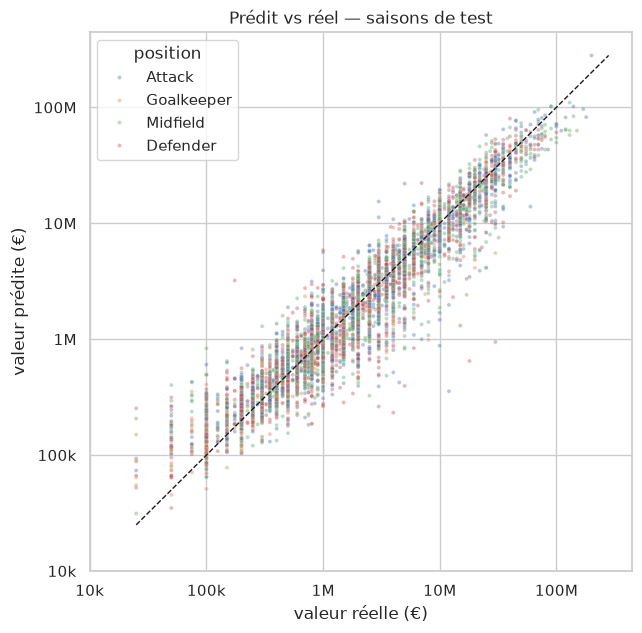

In [25]:
sample = pred.select(T.LABEL, "prediction", "position").sample(0.3, seed=3).toPandas()
fig, ax = plt.subplots(figsize=(7, 7))
sns.scatterplot(data=sample, x=T.LABEL, y="prediction", hue="position", s=8, alpha=0.4, ax=ax)
lims = [sample[[T.LABEL, "prediction"]].min().min(), sample[[T.LABEL, "prediction"]].max().max()]
ax.plot(lims, lims, "k--", lw=1)
ticks = [10_000, 100_000, 1_000_000, 10_000_000, 100_000_000]
import numpy as np
ax.set_xticks(np.log1p(ticks)); ax.set_yticks(np.log1p(ticks))
ax.set_xticklabels(["10k", "100k", "1M", "10M", "100M"]); ax.set_yticklabels(["10k", "100k", "1M", "10M", "100M"])
ax.set_xlabel("valeur réelle (€)"); ax.set_ylabel("valeur prédite (€)"); ax.set_title("Prédit vs réel — saisons de test")
plt.show()

### 6.2 Importance des variables (GBT)

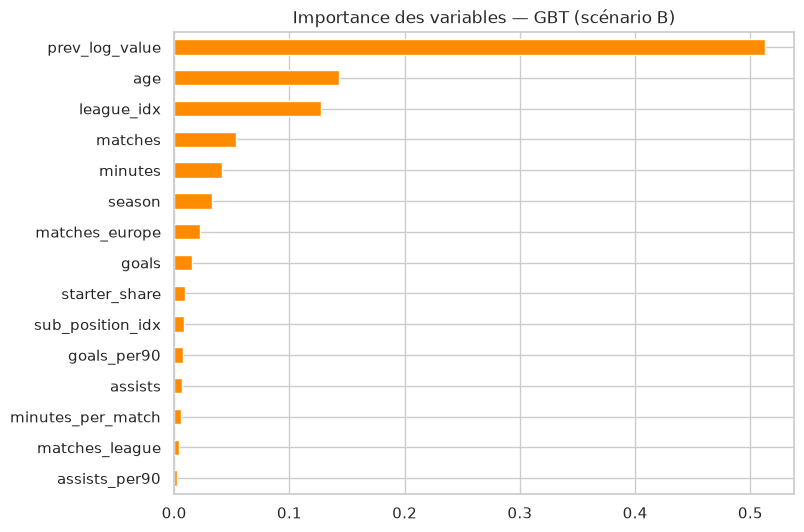

In [26]:
gbt_model = best_model.stages[-1]
attrs = best_model.transform(test.limit(1)).schema["features"].metadata["ml_attr"]["attrs"]
names = {a["idx"]: a["name"] for kind in attrs.values() for a in kind}
imp = pd.Series({names[i]: w for i, w in enumerate(gbt_model.featureImportances.toArray())}).sort_values()
imp.tail(15).plot.barh(figsize=(8, 6), color="darkorange", title="Importance des variables — GBT (scénario B)")
plt.show()

### 6.3 Où le modèle se trompe-t-il ?

In [27]:
err = (pred.withColumn("abs_log_err", F.abs(F.col("prediction") - F.col(T.LABEL)))
           .groupBy("position").agg(F.avg("abs_log_err").alias("MAE (log)"), F.count("*").alias("n"))
           .orderBy("MAE (log)").toPandas())
err

,position,MAE (log),n
0,Defender,0.342853,6850
1,Midfield,0.345597,5744
2,Attack,0.350445,5503
3,Goalkeeper,0.360765,1774


In [28]:
(pred.withColumn("ratio", F.col("pred_value") / F.col("market_value"))
     .filter("minutes >= 1500 AND season = 2025")
     .select("name", "club_name", "position", F.round("age", 1).alias("age"), "goals", "assists",
             (F.col("market_value") / 1e6).alias("valeur TM (M€)"), F.round(F.col("pred_value") / 1e6, 1).alias("estimée (M€)"),
             F.round("ratio", 2).alias("ratio"))
     .orderBy(F.desc("ratio")).limit(10).toPandas())

,name,club_name,position,age,goals,assists,valeur TM (M€),estimée (M€),ratio
0,Ryan McGowan,Livingston FC,Defender,36.8,0,1,0.025,0.1,4.85
1,Lasse Nielsen,Vejle Boldklub,Defender,38.4,0,0,0.025,0.1,4.76
2,James Tavernier,Rangers FC,Defender,34.6,12,5,0.500,2.3,4.67
3,Kasper Schmeichel,Celtic FC,Goalkeeper,39.5,0,0,0.150,0.6,4.11
4,Jérôme Prior,Livingston FC,Goalkeeper,30.8,0,1,0.150,0.6,3.74
5,Declan John,St. Mirren FC,Defender,30.9,1,6,0.150,0.5,3.39
6,Ivan Mesik,Heracles Almelo,Defender,25.0,2,2,0.600,2.0,3.32
7,Zico Buurmeester,PEC Zwolle,Midfield,24.0,2,0,1.300,4.2,3.24
8,Drey Wright,Dundee FC,Midfield,31.1,2,2,0.075,0.2,3.17
9,Graeme Shinnie,Aberdeen FC,Midfield,34.8,1,2,0.100,0.3,3.15


Ces « erreurs » sont en partie **informatives** : un joueur dont la saison justifierait une valeur bien plus élevée que celle affichée est un **candidat à une revalorisation** (ou à une bonne affaire au mercato). C'est l'usage proposé dans l'app.

## [Déploiement]

## 7. Déploiement

1. **Sauvegarde du pipeline Spark complet** (indexeurs + imputer + assembleur + GBT) dans `models/market_value_model/` (+ archive `market_value_model.zip` versionnée sur GitHub).
2. **Job batch** `src/score.py` (lancé avec `spark-submit` ou `python`) : recharge le modèle, recalcule les features de la dernière saison avec le même code (`src/features.py`) et écrit les prédictions.
3. **App Streamlit** `app/streamlit_app.py` : lit ces prédictions (pas besoin de Spark côté web → déploiement gratuit sur Streamlit Community Cloud).

C'est l'architecture classique du ML big data : **entraînement et scoring distribués en batch**, service léger pour la consultation.

In [29]:
MODEL_DIR = ROOT / "models" / "market_value_model"
best_model.write().overwrite().save(str(MODEL_DIR))
# Archive zip versionnée sur GitHub (noms de fichiers Spark trop longs pour Windows)
import shutil
shutil.make_archive(str(MODEL_DIR), "zip", MODEL_DIR)
metadata = {
    "model": "GBTRegressor (Spark ML)", "scenario": BEST_SCENARIO, "params": best_params,
    "train_seasons": "2013-2022", "test_seasons": "2023-2025",
    "train_rows": train.count(), "test_rows": test.count(),
    "metrics_test": {k: round(float(v), 4) for k, v in best_metrics.items()},
    "spark_version": spark.version,
}
(ROOT / "models" / "metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False))
metadata

{'model': 'GBTRegressor (Spark ML)',
 'scenario': 'B — A + valeur précédente',
 'params': {'maxDepth': 5, 'maxIter': 120},
 'train_seasons': '2013-2022',
 'test_seasons': '2023-2025',
 'train_rows': 59771,
 'test_rows': 19871,
 'metrics_test': {'rmse': 0.4824,
  'mae': 0.3473,
  'r2': 0.9064,
  'erreur absolue médiane (€)': 374558.8942,
  'erreur relative médiane': 0.2514,
  'part à ±30 %': 0.5748},
 'spark_version': '4.0.1'}

In [30]:
# Lance le job de scoring (équivalent à : spark-submit src/score.py)
import subprocess
out = subprocess.run([sys.executable, str(ROOT / "src" / "score.py")], capture_output=True, text=True, cwd=ROOT)
print(out.stdout[-500:] or out.stderr[-2000:])
pd.read_csv(ROOT / "app" / "data" / "predictions.csv.gz").head()

Saison 2025 : 7333 joueurs scorés -> /mnt/d/Cours/Marseille/5A/big_data/tp3/Big/app/data



,player_id,name,club_name,league,league_name,position,sub_position,foot,age,season,matches,minutes,goals,assists,matches_europe,market_value,predicted_value,image_url,ratio
0,12589,Craig Gordon,Heart of Midlothian FC,SC1,Scottish Premiership — Scotland,Goalkeeper,Goalkeeper,left,43.4,2025,3,225,0,0,0,50000,45000.0,https://img.a.transfermarkt.technology/portrai...,0.900
1,16306,Casemiro,Manchester United,GB1,Premier League — England,Midfield,Defensive Midfield,right,34.3,2025,38,2800,9,2,0,6000000,5474000.0,https://img.a.transfermarkt.technology/portrai...,0.912
2,27493,Iván Cuéllar,RCD Mallorca,ES1,Laliga — Spain,Goalkeeper,Goalkeeper,left,42.0,2025,1,90,0,0,0,100000,80000.0,https://img.a.transfermarkt.technology/portrai...,0.800
3,29241,Thiago Silva,FC Porto,PO1,Liga Portugal — Portugal,Defender,Centre-Back,right,41.7,2025,14,1116,0,0,4,500000,247000.0,https://img.a.transfermarkt.technology/portrai...,0.494
4,34296,Athanasios Papageorgiou,AE Larisa,GR1,Super League 1 — Greece,Defender,Right-Back,both,39.1,2025,8,554,0,1,0,25000,66000.0,https://img.a.transfermarkt.technology/portrai...,2.640


## [Conclusion]

## Conclusion

- **Spark** a permis de traiter l'ensemble du dataset (≈ 930 Mo, 1,9 M de matchs, 656 000 évaluations) : conversion Parquet, agrégations, fonctions de fenêtre, jointures broadcast, puis entraînement et validation croisée **distribués**.
- Le **scénario A** (performances + profil uniquement) explique déjà une bonne part de la valeur ; ajouter **l'historique** (scénario B) réduit fortement l'erreur — la valeur Transfermarkt évolue par petites touches.
- Le **découpage temporel** donne une évaluation honnête (prédire le futur à partir du passé).
- **Limites** : la valeur Transfermarkt est une *estimation* d'experts, pas un prix de transfert ; le niveau du club, les blessures ou la durée de contrat ne sont pas (ou peu) pris en compte ; le dataset s'arrête en juillet 2026.
- **Pourquoi Spark ici et pas en partie 1 ?** Les tables brutes ne tiennent pas confortablement en mémoire avec pandas sur une machine modeste, et surtout le même code passerait à l'échelle sur un cluster pour des données 100× plus grosses (ex. données de tracking à 25 images/s).

### Comparaison avec les notebooks d'origine (pandas / scikit-learn)

| | Notebooks d'origine | Ce notebook (PySpark) |
|---|---|---|
| Outils | pandas, scikit-learn | Spark : Parquet, Spark SQL, fenêtres, Spark ML |
| Lignes d'entraînement | 1 ligne par joueur actif en 2025 (≈ 18 400 joueurs) | 79 642 lignes joueur × saison (2013-2025) |
| Historique des valeurs | non utilisé | dernière valeur de chaque saison + valeur précédente (`lag`) |
| Découpage | aléatoire (80 / 20) | temporel (2013-2022 / 2023-2025) |
| Meilleur modèle | Gradient Boosting optimisé, R² = 0,736 | GBT optimisé : R² = 0,734 (A), **0,906** (B) |
| Déploiement | app Flask décrite, mais `app.py` absent | job Spark batch + app Streamlit + Docker |

Sans la valeur précédente, les deux approches arrivent au même niveau (R² ≈ 0,73), mais la nôtre est évaluée sur des saisons futures, ce qui est plus exigeant. L'apport principal de Spark est de pouvoir exploiter **tout l'historique** (1,9 M de matchs, 656 000 évaluations) au lieu d'une seule photo des données.